# T09 · Graphiques pédagogiques — ADIF72

Visualisations des concepts clés. Chaque figure illustre un point
théorique du cours. En Colab, les graphiques s'affichent **inline**
(`%matplotlib inline`).

Les 8 figures :
1. TCL — effet de la taille d'échantillon
2. Descente de gradient — trajectoire 2D
3. PCA — SVD + projection
4. Distributions — Normal / Binomiale / Exponentielle / Bêta
5. Bayes — prior Bêta → posteriors
6. Couverture des intervalles de confiance
7. Sur-apprentissage — biais-variance
8. Learning curves — linéaire vs forêt

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import learning_curve
from sklearn.preprocessing import PolynomialFeatures
rng = np.random.default_rng(7)
plt.rcParams['figure.figsize'] = (8, 5)
print("Matplotlib prêt.")

Matplotlib prêt.


### Fig 1 — Théorème de la limite centrale

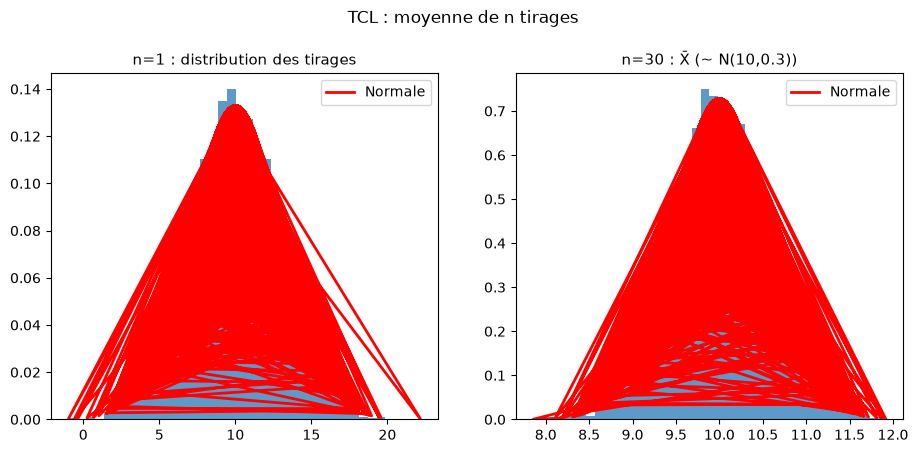

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
mu, sigma = 10, 3
n_samps = 5000
for n, ax, title in [(1, axes[0], 'n=1 : distribution des tirages'),
                     (30, axes[1], f'n=30 : X̄ (~ N({mu},{sigma**2/30}))')]:
    data = rng.normal(mu, sigma, n_samps) if n==1 else rng.normal(mu, sigma, (n_samps, n)).mean(axis=1)
    ax.hist(data, bins=40, density=True, alpha=0.75, color='#2878b5')
    pdf = stats.norm.pdf(data, mu, sigma if n==1 else sigma/np.sqrt(n))
    ax.plot(data, pdf, 'r-', lw=2, label='Normale')
    ax.set_title(title, fontsize=11); ax.legend()
fig.suptitle('TCL : moyenne de n tirages', y=1.02)
plt.show()

### Fig 2 — Trajectoire de descente de gradient

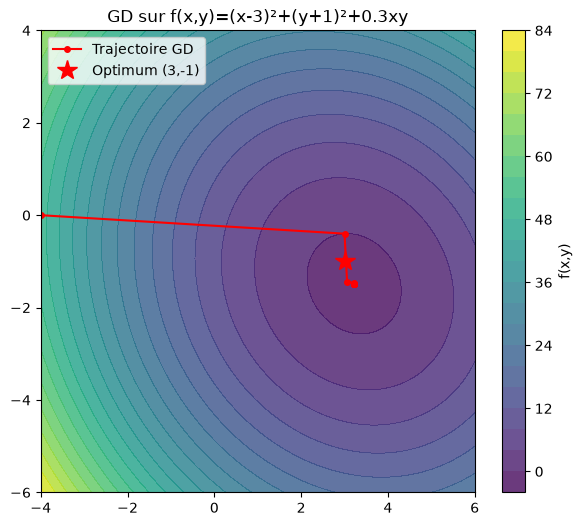

In [3]:
f2 = lambda x, y: (x-3)**2 + (y+1)**2 + 0.3*x*y
df2 = lambda x, y: np.array([2*(x-3)+0.3*y, 2*(y+1)+0.3*x])
xx, yy = np.meshgrid(np.linspace(-4,6,200), np.linspace(-6,4,200))
traj = np.array([[-4.0, 0.0]])
for _ in range(40):
    x, y = traj[-1]; g = df2(x, y)
    traj = np.vstack([traj, [x-0.5*g[0], y-0.5*g[1]]])
fig, ax = plt.subplots(figsize=(7,6))
cont = ax.contourf(xx, yy, f2(xx, yy), levels=20, cmap='viridis', alpha=0.8)
ax.plot(traj[:,0], traj[:,1], 'r-o', ms=4, lw=1.5, label='Trajectoire GD')
ax.plot(3, -1, 'r*', ms=15, label='Optimum (3,-1)')
fig.colorbar(cont, ax=ax, label='f(x,y)')
ax.set_title('GD sur f(x,y)=(x-3)²+(y+1)²+0.3xy'); ax.legend(loc='upper left')
plt.show()

### Fig 3 — PCA (SVD)

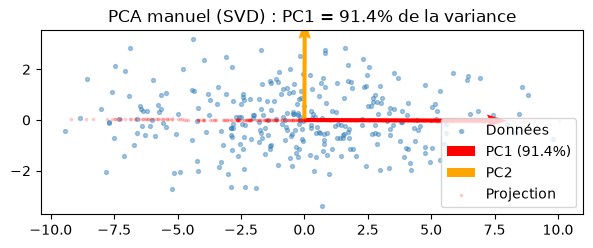

In [4]:
pts = rng.normal(0,1,(300,2))*np.array([4,1.2])
Xc = pts - pts.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
pc1, pc2 = Vt[0], Vt[1]
proj1 = Xc @ pc1
var_expl = (S[0]**2)/np.sum(S**2)*100
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(pts[:,0], pts[:,1], s=8, alpha=0.4, color='#2878b5', label='Données')
ax.quiver(0,0, pc1[0]*8, pc1[1]*8, angles='xy', scale_units='xy', scale=1, color='red', lw=2, label=f'PC1 ({var_expl:.1f}%)')
ax.quiver(0,0, pc2[0]*4, pc2[1]*4, angles='xy', scale_units='xy', scale=1, color='orange', lw=2, label='PC2')
ax.scatter(proj1*pc1[0], proj1*pc1[1], s=3, alpha=0.15, color='red', label='Projection')
ax.set_title(f'PCA manuel (SVD) : PC1 = {var_expl:.1f}% de la variance'); ax.legend(); ax.set_aspect('equal')
plt.show()

### Fig 4 — Distributions usuelles

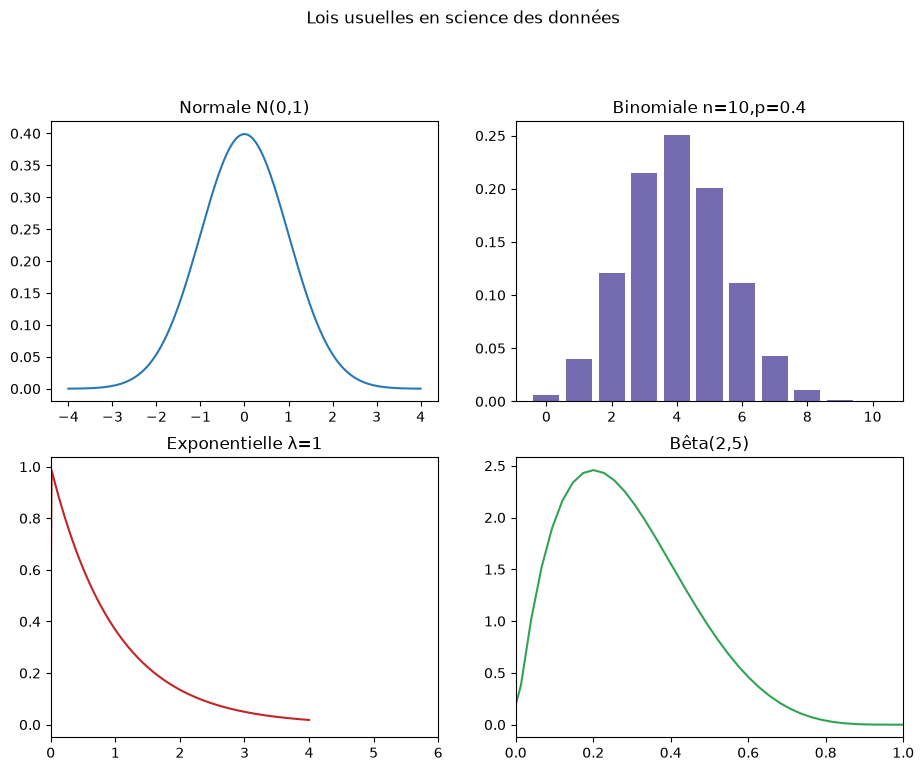

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
x = np.linspace(-4, 4, 300)
axes[0,0].plot(x, stats.norm.pdf(x), color='#2878b5'); axes[0,0].set_title('Normale N(0,1)')
axes[0,1].bar(np.arange(0,11), stats.binom.pmf(np.arange(0,11), 10, 0.4), color='#756bb1'); axes[0,1].set_title('Binomiale n=10,p=0.4')
axes[1,0].plot(x, stats.expon.pdf(x, scale=1), color='#c12526'); axes[1,0].set_xlim(0,6); axes[1,0].set_title('Exponentielle λ=1')
axes[1,1].plot(x, stats.beta.pdf(x, 2, 5), color='#31a354'); axes[1,1].set_xlim(0,1); axes[1,1].set_title('Bêta(2,5)')
fig.suptitle('Lois usuelles en science des données', y=1.02)
plt.show()

### Fig 5 — Mise à jour bayésienne (Bêta)

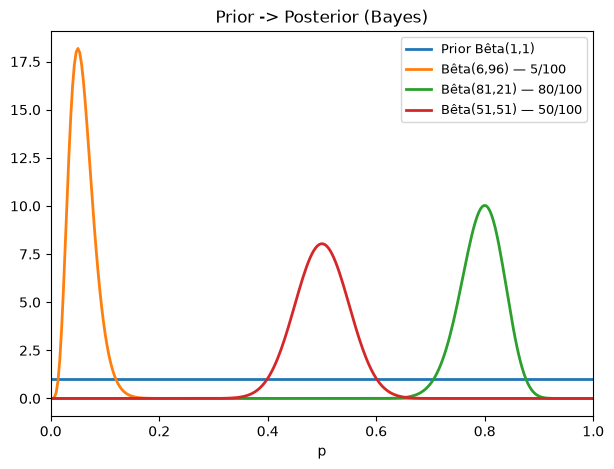

In [6]:
fig, ax = plt.subplots(figsize=(7,5))
x = np.linspace(0,1,300)
ax.plot(x, stats.beta.pdf(x,1,1), lw=2, label='Prior Bêta(1,1)')
for s,t,col in [(5,100,'#2878b5'),(80,100,'#c12526'),(50,100,'#31a354')]:
    ax.plot(x, stats.beta.pdf(x,1+s,1+t-s), lw=2, label=f'Bêta({1+s},{1+t-s}) — {s}/{t}')
ax.set_xlim(0,1); ax.set_xlabel('p'); ax.set_title('Prior -> Posterior (Bayes)'); ax.legend(fontsize=9)
plt.show()

### Fig 6 — Couverture des intervalles de confiance

n=10 : couverture = 0.9470 (≈ 95%)
n=30 : couverture = 0.9540 (≈ 95%)
n=100 : couverture = 0.9530 (≈ 95%)


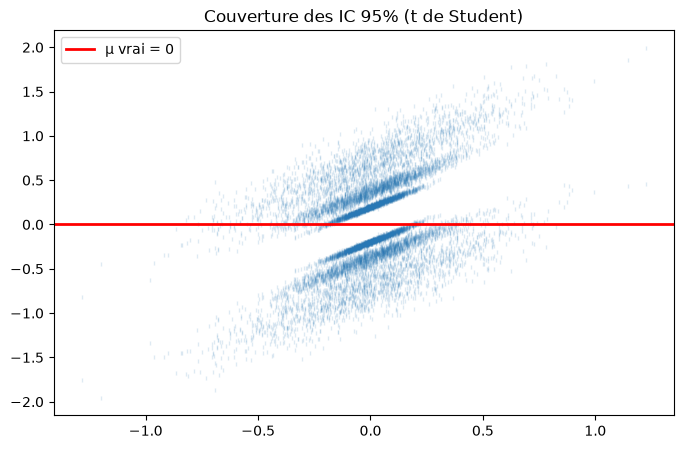

In [7]:
mu_true, sigma_true = 0, 1
N = 2000
fig, ax = plt.subplots(figsize=(8,5))
for n in [10, 30, 100]:
    means, halves = [], []
    for _ in range(N):
        s = rng.normal(mu_true, sigma_true, n)
        mb, ss = s.mean(), s.std(ddof=1)
        means.append(mb); halves.append(stats.t.ppf(0.975, n-1)*ss/np.sqrt(n))
    means, halves = np.array(means), np.array(halves)
    cov = np.mean((means-halves<=0)&(means+halves>=0))
    ax.plot(means, means+halves, '|', color='#2878b5', alpha=0.15, ms=3)
    ax.plot(means, means-halves, '|', color='#2878b5', alpha=0.15, ms=3)
    print(f"n={n} : couverture = {cov:.4f} (≈ 95%)")
ax.axhline(0, color='r', lw=2, label='μ vrai = 0')
ax.set_title('Couverture des IC 95% (t de Student)'); ax.legend()
plt.show()

### Fig 7 — Biais-variance (degré polynôme)

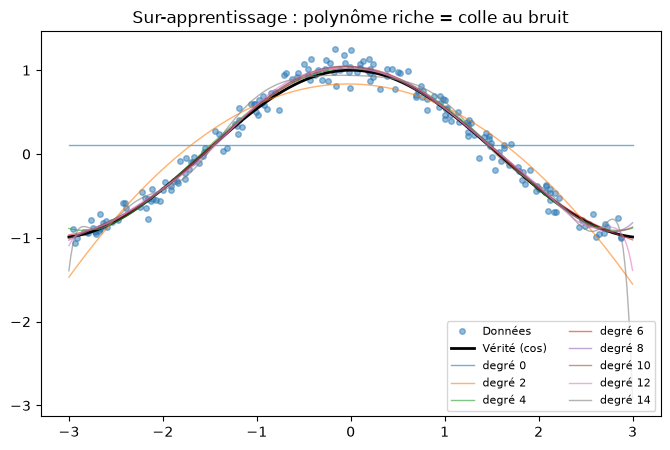

In [8]:
xp = rng.uniform(-3,3,200); yp = np.cos(xp)+rng.normal(0,0.1,200)
Xp = xp.reshape(-1,1); xx = np.linspace(-3,3,300).reshape(-1,1)
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(xp, yp, 'o', ms=4, alpha=0.5, color='#2878b5', label='Données')
ax.plot(xx, np.cos(xx), 'k-', lw=2, label='Vérité (cos)')
for deg in range(0, 16, 2):
    P = PolynomialFeatures(deg).fit_transform(Xp)
    m = LinearRegression().fit(P, yp)
    Pxx = PolynomialFeatures(deg).fit_transform(xx)
    ax.plot(xx, m.predict(Pxx), '-', lw=1, alpha=0.6, label=f'degré {deg}')
ax.set_title('Sur-apprentissage : polynôme riche = colle au bruit'); ax.legend(loc='lower right', fontsize=8, ncols=2)
plt.show()

### Fig 8 — Learning curves

/tmp/ipykernel_3584070/3014535732.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "s-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(lc[0], vs, 's-', color=col, lw=2, ls='--', label=f'{name} — validation')


/tmp/ipykernel_3584070/3014535732.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "s-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(lc[0], vs, 's-', color=col, lw=2, ls='--', label=f'{name} — validation')


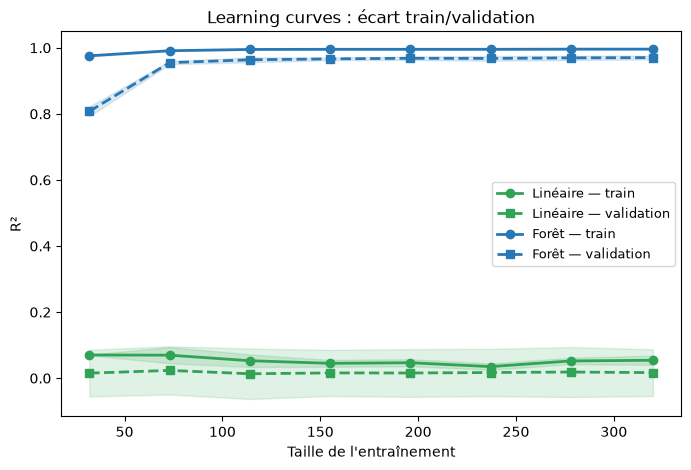

In [9]:
Xnl = rng.uniform(0,1,(400,1)); ynl = np.sin(6*np.pi*Xnl[:,0])+rng.normal(0,0.1,400)
fig, ax = plt.subplots(figsize=(8,5))
for name, m, col in [('Linéaire', LinearRegression(), '#31a354'),
                     ('Forêt', RandomForestRegressor(n_estimators=50, random_state=7), '#2878b5')]:
    lc = learning_curve(m, Xnl, ynl, cv=5, train_sizes=np.linspace(0.1,1.0,8), scoring='r2', random_state=7)
    ts, vs = lc[1].mean(axis=1), lc[2].mean(axis=1)
    tse, vse = lc[1].std(axis=1), lc[2].std(axis=1)
    ax.plot(lc[0], ts, 'o-', color=col, lw=2, label=f'{name} — train')
    ax.plot(lc[0], vs, 's-', color=col, lw=2, ls='--', label=f'{name} — validation')
    ax.fill_between(lc[0], ts-tse, ts+tse, alpha=0.15, color=col)
    ax.fill_between(lc[0], vs-vse, vs+vse, alpha=0.15, color=col)
ax.set_xlabel('Taille de l\'entraînement'); ax.set_ylabel('R²')
ax.set_title('Learning curves : écart train/validation'); ax.legend(fontsize=9)
plt.show()

In [10]:
print("✅ T09 terminé. 8 figures générées.")

✅ T09 terminé. 8 figures générées.
